# 05 · Confounding: vì sao dữ liệu cũ đánh giá voucher quá cao

Dữ liệu `legacy_28d` (W0, quy mô Hà Nội, tiền VND; `runs/s8/w0`) sinh từ **luật phát voucher cũ**. Luật này nhắm rider theo tần suất đặt xe *và* theo một biến ẩn `u_latent`, mà `u_latent` cũng làm rider hay hoàn thành chuyến hơn. Notebook trả lời ba câu:

1. So thô, điều chỉnh theo đặc trưng quan sát được, và DR-learner lệch bao nhiêu so với lát explore (phát ngẫu nhiên)?
2. Độ lệch đến từ đâu?
3. Độ lệch thay đổi thế nào khi luật cũ nhắm `u_latent` mạnh hay yếu?

Mọi phép tính nằm trong `analysis/` (có test). Mục 2 đọc `u_latent` từ `hidden/` **chỉ để chẩn đoán** (`analysis/io.py`); không mô hình hay chính sách nào dùng nó. Liên quan: notebook 03 (cách đo độ nhạy theo `target_g_u`), notebook 04 (DR-learner, hệ quả cho chính sách).

In [1]:
import numpy as np
import pandas as pd

from analysis import uplift
from analysis.confounding import decompose_naive, latent_profile
from analysis.interference import confounding_estimates, confounding_table
from analysis.notebook import require_runs, setup
from analysis.plots import GRID, INK, INK_2, MUTED, save_figure

plt = setup()
LEGACY, GU_0, GU_05, GU_2 = require_runs("runs/s8/w0/legacy_28d", "runs/s8/w0/legacy_gu_0_28d",
                                         "runs/s8/w0/legacy_gu_0p5_28d", "runs/s8/w0/legacy_gu_2_28d")
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"     # categorical slots 1-3 of the house palette (analysis/plots.py)

## 1. Các ước lượng trên dữ liệu cũ (`legacy_28d`, `target_g_u` = 1)

Kết cục là tỷ lệ hoàn thành của một session; hiệu ứng là có voucher trừ không voucher.

| Ước lượng | Cách tính |
|---|---|
| **lát explore** | 5% session được phát *ngẫu nhiên* (xác suất 0,5): không nhiễu, dùng làm mốc |
| so thô | có voucher trừ không voucher, trên các session theo luật cũ |
| điều chỉnh theo X | như trên nhưng so trong từng tầng `x_segment` × thập phân vị `x_freq`, chỉ ô đang bật voucher |
| DR toàn bộ / DR explore | DR-learner (notebook 04, mục 1) trên toàn bộ legacy / chỉ lát explore |

In [2]:
est = confounding_estimates(LEGACY, n_boot=200)
models = {name: uplift.load_model(name)[0] for name in ("dr_all", "dr_explore")}
estimates = pd.DataFrame([
    {"ước lượng": "so thô (luật cũ)", "hiệu ứng": est["naive"], "mốc": "explore, mọi ô", "chệch": est["bias_naive"],
     "CI chệch": (est["bias_naive_lo"], est["bias_naive_hi"])},
    {"ước lượng": "điều chỉnh theo X", "hiệu ứng": est["adjusted"], "mốc": "explore, ô bật", "chệch": est["bias_adjusted"],
     "CI chệch": (est["bias_adjusted_lo"], est["bias_adjusted_hi"])},
    {"ước lượng": "DR toàn bộ legacy", "hiệu ứng": models["dr_all"]["ate_dr"], "mốc": "explore, mọi ô",
     "chệch": models["dr_all"]["ate_dr"] - est["explore_all"], "CI chệch": None},
    {"ước lượng": "DR lát explore", "hiệu ứng": models["dr_explore"]["ate_dr"], "mốc": "explore, mọi ô",
     "chệch": models["dr_explore"]["ate_dr"] - est["explore_all"], "CI chệch": None},
    {"ước lượng": "lát explore, mọi ô", "hiệu ứng": est["explore_all"], "mốc": "—", "chệch": 0.0, "CI chệch": None},
    {"ước lượng": "lát explore, ô bật", "hiệu ứng": est["explore_on"], "mốc": "—", "chệch": 0.0, "CI chệch": None},
])
print(f"Tỷ lệ session được phát theo luật cũ: {100 * est['share_offered']:.1f}%; lát explore: {est['n_explore']:,} session")
estimates.round(4)

Tỷ lệ session được phát theo luật cũ: 21.1%; lát explore: 205,624 session


,ước lượng,hiệu ứng,mốc,chệch,CI chệch
0,so thô (luật cũ),0.0909,"explore, mọi ô",0.0352,"(0.03211738150141076, 0.03853249447150492)"
1,điều chỉnh theo X,0.1065,"explore, ô bật",0.0484,"(0.044508848206136764, 0.052527761855770766)"
2,DR toàn bộ legacy,0.0930,"explore, mọi ô",0.0374,None
3,DR lát explore,0.0584,"explore, mọi ô",0.0027,None
4,"lát explore, mọi ô",0.0556,—,0.0000,None
5,"lát explore, ô bật",0.0581,—,0.0000,None


WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/05_uoc_luong_legacy.png')

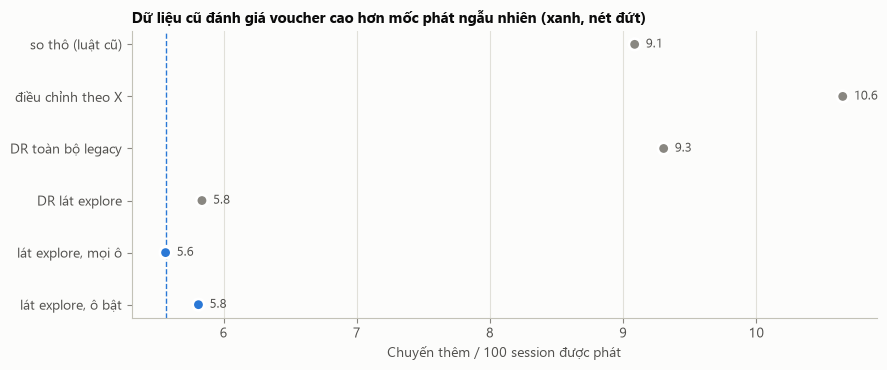

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = estimates.iloc[::-1].reset_index(drop=True)
y = np.arange(len(order))
colors = [C1 if name.startswith("lát explore") else MUTED for name in order["ước lượng"]]
ax.scatter(100 * order["hiệu ứng"], y, color=colors, s=70, zorder=3, edgecolor="white", linewidth=2)
ax.axvline(100 * est["explore_all"], color=C1, linewidth=1, linestyle="--")
for yi, v in zip(y, order["hiệu ứng"]):
    ax.annotate(f"{100 * v:.1f}", xy=(100 * v, yi), xytext=(8, 0), textcoords="offset points", va="center",
                color=INK_2, fontsize=9)
ax.set_yticks(y, order["ước lượng"])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID)
ax.set_xlabel("Chuyến thêm / 100 session được phát")
ax.set_title("Dữ liệu cũ đánh giá voucher cao hơn mốc phát ngẫu nhiên (xanh, nét đứt)")
fig.tight_layout()
save_figure(fig, "05_uoc_luong_legacy")

- So thô cao hơn lát explore 0,035 chuyến mỗi session (+0,0909 so với +0,0556), tức **+63% so với mốc không gây nhiễu**.
- **Điều chỉnh theo X không gỡ được** độ lệch, thậm chí chệch hơn trên đúng mốc của nó (+0,1065 so với +0,0581 ở ô bật: +0,048).
- DR-learner học trên toàn bộ dữ liệu cũ (ATE 0,093) cũng chệch như so thô; DR học trên lát explore (0,058) trùng mốc. Kết luận giống trên thành phố cũ (0,036 / 0,043): quy mô Hà Nội và tiền VND không đổi cơ chế.


## 2. Cơ chế: luật cũ phát cho ai?

Chia rider thành 10 nhóm bằng nhau theo `u_latent` (đọc từ `hidden/`, chỉ để chẩn đoán).

In [4]:
profile = latent_profile(LEGACY, n_bins=10)
profile.round(4)

,bin,u_mid,sessions,share_offered,rate_not_offered,rate_offered,naive,explore_effect
0,0,-1.6532,418233,0.0500,0.0699,0.0856,0.0157,0.0203
1,1,-1.0451,417875,0.0888,0.0880,0.1093,0.0213,0.0269
2,2,-0.6779,413417,0.1211,0.0978,0.1291,0.0313,0.0382
3,3,-0.3853,417635,0.1492,0.1115,0.1449,0.0334,0.0369
4,4,-0.1287,414302,0.1800,0.1164,0.1621,0.0458,0.0521
5,5,0.1259,413843,0.2133,0.1261,0.1785,0.0524,0.0557
6,6,0.3879,413358,0.2475,0.1389,0.1972,0.0583,0.0601
7,7,0.6768,413696,0.2888,0.1476,0.2120,0.0643,0.0681
8,8,1.0455,411732,0.3439,0.1645,0.2470,0.0825,0.0872
9,9,1.6541,411856,0.4362,0.1932,0.3077,0.1145,0.1110


WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/05_co_che_u_latent.png')

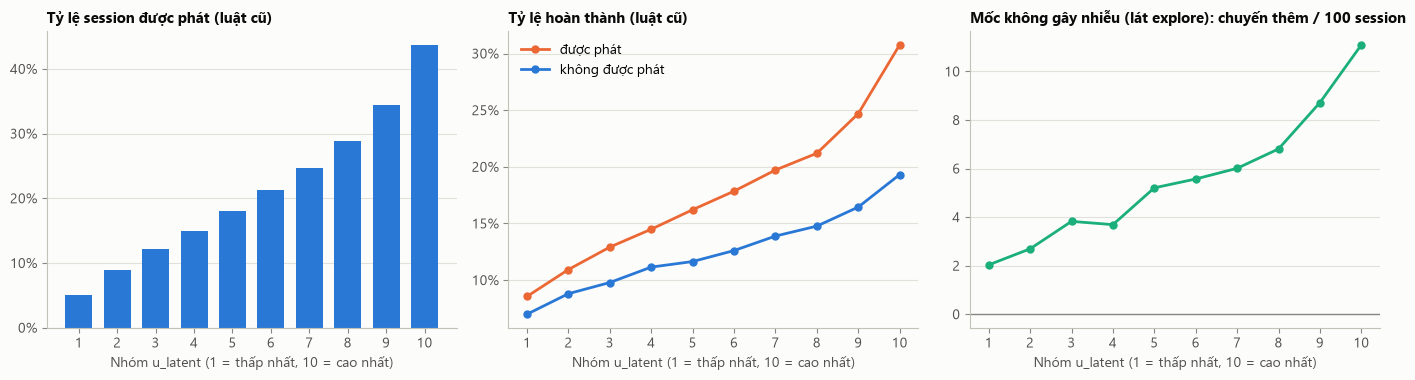

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
x = profile["bin"] + 1
axes[0].bar(x, 100 * profile["share_offered"], color=C1, width=0.7)
axes[0].set_title("Tỷ lệ session được phát (luật cũ)")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
for col, name, color in (("rate_offered", "được phát", C2), ("rate_not_offered", "không được phát", C1)):
    axes[1].plot(x, 100 * profile[col], color=color, linewidth=2, marker="o", markersize=5, label=name)
axes[1].set_title("Tỷ lệ hoàn thành (luật cũ)")
axes[1].legend(frameon=False, loc="upper left")
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
axes[2].plot(x, 100 * profile["explore_effect"], color=C3, linewidth=2, marker="o", markersize=5)
axes[2].set_title("Mốc không gây nhiễu (lát explore): chuyến thêm / 100 session")
axes[2].axhline(0, color=MUTED, linewidth=1)
for ax in axes:
    ax.set_xlabel("Nhóm u_latent (1 = thấp nhất, 10 = cao nhất)")
    ax.set_xticks(x)
fig.tight_layout()
save_figure(fig, "05_co_che_u_latent")

Ba điều cùng lúc:
1. Luật cũ phát cho rider `u_latent` cao nhiều hơn hẳn (trái).
2. Rider `u_latent` cao hoàn thành chuyến nhiều hơn **kể cả khi không có voucher** (giữa, đường xanh).
3. Hiệu ứng voucher đo trên lát explore (mốc không gây nhiễu) cũng lớn hơn ở rider `u_latent` cao (phải).

(2) là **nhiễu chọn lọc**: so người được phát với người không được phát là so hai nhóm vốn khác nhau. (3) làm so thô đo *hiệu ứng trên người được phát* (ATT) thay vì *hiệu ứng trung bình* (ATE).

## 3. Tách độ lệch của so thô

Hai phần trên tách được bằng các hiệu ứng explore trong từng nhóm `u_latent` (`analysis.confounding.decompose_naive`).

In [6]:
parts = decompose_naive(profile)
parts.assign(**{"chuyến / 100 session": 100 * parts["value"]}).round(4)

,part,value,chuyến / 100 session
0,ate,0.0555,5.5526
1,targeting (att - ate),0.0141,1.4088
2,within-bin residual (naive_within_u - att),-0.0026,-0.2603
3,selection on u_latent (naive - naive_within_u),0.0238,2.3847
4,naive,0.0909,9.0858


WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/05_tach_do_lech.png')

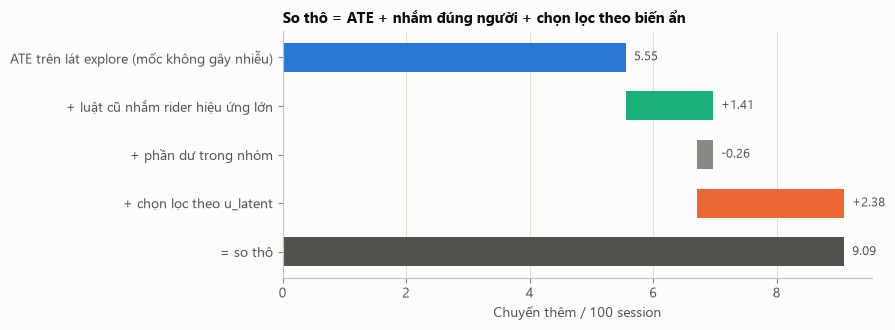

In [7]:
names = {"ate": "ATE trên lát explore (mốc không gây nhiễu)", "targeting (att - ate)": "+ luật cũ nhắm rider hiệu ứng lớn",
         "within-bin residual (naive_within_u - att)": "+ phần dư trong nhóm",
         "selection on u_latent (naive - naive_within_u)": "+ chọn lọc theo u_latent", "naive": "= so thô"}
fig, ax = plt.subplots(figsize=(9, 3.4))
values = 100 * parts["value"].to_numpy()
start = np.r_[0.0, np.cumsum(values[:3]), 0.0]
colors = [C1, C3, MUTED, C2, INK_2]
y = np.arange(len(values))[::-1]
ax.barh(y, values, left=start, color=colors, height=0.6)
for yi, s, v in zip(y, start, values):
    ax.annotate(f"{v:+.2f}" if 0 < yi < len(values) - 1 else f"{v:.2f}", xy=(s + max(v, 0), yi), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.set_yticks(y, [names[p] for p in parts["part"]])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID)
ax.set_xlabel("Chuyến thêm / 100 session")
ax.set_title("So thô = ATE + nhắm đúng người + chọn lọc theo biến ẩn")
fig.tight_layout()
save_figure(fig, "05_tach_do_lech")

- Trên W0 (`target_g_u` = 1): so thô 9,09 chuyến / 100 session = ATE 5,55 + nhắm rider hiệu ứng lớn +1,41 + phần dư trong nhóm −0,26 + **chọn lọc theo `u_latent` +2,38**.
- Phần "nhắm rider hiệu ứng lớn" **không phải sai số**: nếu câu hỏi là "voucher giúp *những người luật cũ đã phát* bao nhiêu" thì ATT (5,55 + 1,41 = 6,96) là đáp án đúng. Nó chỉ sai khi đem dùng cho cả quần thể (ATE).
- Phần "chọn lọc theo `u_latent`" là sai số thật: rider `u_latent` cao hoàn thành nhiều hơn dù không có voucher, và luật cũ phát cho họ nhiều hơn. Phần này lớn hơn phần nhắm đúng người (2,38 so với 1,41) và không đo được từ dữ liệu quan sát.


## 4. Độ lệch theo độ mạnh của việc nhắm `u_latent`

Sinh lại dữ liệu cũ với cùng 4.195.499 session (W0, CRN), chỉ đổi hệ số nhắm `policy.legacy.target_g_u`: 0 (không nhắm theo `u_latent`), 0,5, 1 (mặc định), 2. Dữ liệu và cách đo dùng chung với notebook 03; notebook đó trình bày cùng số liệu dưới góc độ thiết kế thí nghiệm.

In [8]:
sens = confounding_table([GU_0, GU_05, LEGACY, GU_2], n_boot=200)
split = pd.DataFrame({g: decompose_naive(latent_profile(d)).set_index("part")["value"]
                      for g, d in zip(sens["target_g_u"], (GU_0, GU_05, LEGACY, GU_2))}).T
sens = sens.set_index("target_g_u").join(split.drop(columns="naive"))   # same naive as the table
sens[["share_offered", "naive", "explore_all", "bias_naive", "adjusted", "explore_on", "bias_adjusted",
      "selection on u_latent (naive - naive_within_u)", "targeting (att - ate)"]].round(4)

,share_offered,naive,explore_all,bias_naive,adjusted,explore_on,bias_adjusted,selection on u_latent (naive - naive_within_u),targeting (att - ate)
target_g_u,,,,,,,,,
0.0,0.2090,0.0503,0.0577,-0.0074,0.0617,0.0608,0.0010,-0.0001,-0.0001
0.5,0.2111,0.0732,0.0586,0.0145,0.0876,0.0622,0.0254,0.0137,0.0081
1.0,0.2113,0.0909,0.0556,0.0352,0.1065,0.0581,0.0484,0.0238,0.0141
2.0,0.2062,0.1126,0.0535,0.0592,0.1259,0.0562,0.0697,0.0328,0.0203


WindowsPath('C:/Work/VinAI/GSM/Supply-Aware-Promotion-Uplift/docs/figures/05_do_nhay_u_latent.png')

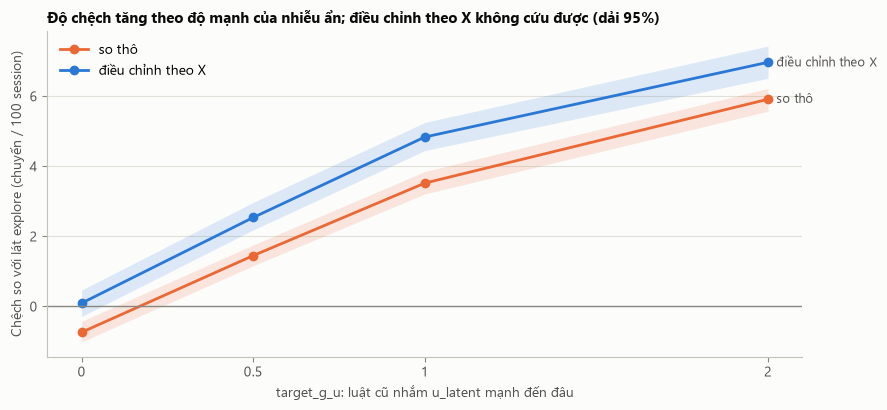

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.2))
g = sens.index.to_numpy()
for col, name, color in (("bias_naive", "so thô", C2), ("bias_adjusted", "điều chỉnh theo X", C1)):
    ax.fill_between(g, 100 * sens[f"{col}_lo"], 100 * sens[f"{col}_hi"], color=color, alpha=0.15, linewidth=0)
    ax.plot(g, 100 * sens[col], color=color, linewidth=2, marker="o", markersize=6, label=name)
    ax.annotate(name, xy=(g[-1], 100 * sens[col].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK_2, fontsize=9)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_xticks(g, [f"{v:g}" for v in g])
ax.set_xlabel("target_g_u: luật cũ nhắm u_latent mạnh đến đâu")
ax.set_ylabel("Chệch so với lát explore (chuyến / 100 session)")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Độ chệch tăng theo độ mạnh của nhiễu ẩn; điều chỉnh theo X không cứu được (dải 95%)")
fig.tight_layout()
save_figure(fig, "05_do_nhay_u_latent")

- Khi luật cũ **không** nhắm theo `u_latent` (`target_g_u` = 0), chệch của so thô là −0,7 và sau điều chỉnh theo X +0,1 chuyến / 100 session: gần hết chệch, nhiễu còn lại chỉ là nhiễu quan sát được.
- Nhắm càng mạnh chệch càng lớn, gần tuyến tính: so thô +1,5 / +3,5 / +5,9 chuyến / 100 session ở `target_g_u` 0,5 / 1 / 2; phần chọn lọc theo `u_latent` +1,37 / +2,38 / +3,28, phần nhắm đúng người +0,81 / +1,41 / +2,03.
- Điều chỉnh theo X **không cứu được** ở mọi mức (chệch sau điều chỉnh +2,5 / +4,8 / +7,0): đặc trưng quan sát được không chứa `u_latent`.


## 5. Kết luận

1. Trên dữ liệu cũ, **so thô, điều chỉnh theo X và DR-learner đều đánh giá voucher cao hơn mốc không gây nhiễu 63–83% (so thô +0,035, điều chỉnh theo X +0,048, DR toàn bộ +0,037 trên mốc 0,056–0,058)**, vì luật cũ nhắm theo biến ẩn `u_latent`. DR-learner chỉ sửa được nhiễu *quan sát được*.
2. Độ lệch gồm hai phần: luật cũ nhắm đúng rider có hiệu ứng lớn (ATT ≠ ATE, không phải sai số nếu hỏi đúng câu) và chọn lọc theo `u_latent` (sai số thật, không gỡ được từ dữ liệu quan sát).
3. **Cách khắc phục là dữ liệu ngẫu nhiên hóa**: lát explore 5% đã đủ cho một ước lượng không chệch của hiệu ứng trung bình. Thí nghiệm A/B và switchback (notebook 03) đo hiệu ứng tổng nhưng có vấn đề riêng là interference.
4. Hệ quả cho chính sách (notebook 04): hàm điểm `tau_x_dr_all_per_kvnd`, học trên toàn bộ legacy, vẫn cho nhiều chuyến nhất dưới B. Chính sách chỉ cần **thứ hạng** rider, không cần mức hiệu ứng đúng; kết quả dưới B cho thấy độ chệch không làm hỏng thứ hạng theo chuyến thêm mỗi 1.000đ đến mức thua các hàm điểm khác. Mọi con số "voucher thêm bao nhiêu chuyến" phải lấy từ dữ liệu ngẫu nhiên hóa, không từ dữ liệu cũ.
6. Trên W1 (có biến động) các con số trùng trong sai số (chệch thô +0,0357, sau điều chỉnh +0,0450 ở `target_g_u` = 1): nhiễu ẩn không phụ thuộc thế giới.
